# CNN + ArcFace — 226 Hand-Specific Classes

This Colab notebook uses:
- 113 people × 2 hands = **226 classes**
- DB1 = **904 images** = 4 images/class
- DB2 = **678 images** = 3 images/class
- DB1 split per class: **3 train + 1 validation**
- DB2: all 3 images/class for cross-session testing
- CNN backbone + joint CE + ArcFace-style angular-margin supervision
- `m = 0.40`, `s = 30`
- seeds: `42, 123, 456, 2026, 777`
- resumable checkpoints after every epoch

In [ ]:
import os, re, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import precision_recall_fscore_support

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DATA_ROOT = Path("/content/drive/MyDrive/DorsalVeinProject/processed_v2")  # change if needed
OUT_DIR = Path("/content/drive/MyDrive/DorsalVeinProject/cnn_arcface_226classes_m40")
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_ROOT.exists(), f"Dataset folder not found: {DATA_ROOT}"

Mounted at /content/drive


In [ ]:
SEEDS = [42, 123, 456, 2026, 777]
NUM_PEOPLE = 113
NUM_CLASSES = 226

IMG_SIZE = 224
BATCH_SIZE = 32
MAX_EPOCHS = 200
LR = 1e-3
WEIGHT_DECAY = 1e-4
EMBED_DIM = 256

ARC_S = 30.0
ARC_M = 0.40

NUM_WORKERS = 0
VALID_HANDS = {"L", "R"}

# Set this to the SAME filter/tag used in your 904/678 experiments
FILTER_TYPE = "roi"

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [ ]:
PATTERN = re.compile(
    r"^person_(\d{3})_db(\d)_([LR])(\d+)_([a-zA-Z]+)\.png$",
    re.IGNORECASE
)

def scan_dataset(root):
    rows = []
    for p in Path(root).rglob("*.png"):
        m = PATTERN.match(p.name)
        if m is None:
            continue

        person = int(m.group(1))
        db = int(m.group(2))
        hand = m.group(3).upper()
        sample = int(m.group(4))
        tag = m.group(5).lower()

        if not (1 <= person <= NUM_PEOPLE):
            continue
        if hand not in VALID_HANDS:
            continue
        if tag != FILTER_TYPE:
            continue

        rows.append({
            "path": str(p),
            "person": person,
            "db": db,
            "hand": hand,
            "sample": sample,
            "tag": tag
        })

    df = pd.DataFrame(rows)
    assert len(df) > 0, "No matching images. Check DATA_ROOT/FILTER_TYPE."
    return df.sort_values(["person","db","hand","sample"]).reset_index(drop=True)

df = scan_dataset(DATA_ROOT)
db1 = df[df.db == 1].copy().reset_index(drop=True)
db2 = df[df.db == 2].copy().reset_index(drop=True)

assert len(db1) == 904, f"Expected DB1=904, got {len(db1)}"
assert len(db2) == 678, f"Expected DB2=678, got {len(db2)}"

def hand_label(person, hand):
    return (person - 1) * 2 + (0 if hand == "L" else 1)

db1["label"] = [hand_label(p,h) for p,h in zip(db1.person, db1.hand)]
db2["label"] = [hand_label(p,h) for p,h in zip(db2.person, db2.hand)]

assert db1.label.nunique() == NUM_CLASSES
assert db2.label.nunique() == NUM_CLASSES
assert (db1.groupby("label").size() == 4).all()
assert (db2.groupby("label").size() == 3).all()

print("DB1:", len(db1), "| DB2:", len(db2), "| classes:", NUM_CLASSES)

DB1: 904 | DB2: 678 | classes: 226


In [ ]:
def split_db1(df):
    tr, va = [], []
    for label in sorted(df.label.unique()):
        c = df[df.label == label].sort_values("sample").reset_index(drop=True)
        assert len(c) == 4
        tr.append(c.iloc[:3])
        va.append(c.iloc[3:4])
    return pd.concat(tr, ignore_index=True), pd.concat(va, ignore_index=True)

train_df, val_df = split_db1(db1)
test_df = db2.copy().reset_index(drop=True)

assert len(train_df) == 678
assert len(val_df) == 226
assert len(test_df) == 678
print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

Train: 678 Val: 226 Test: 678


In [ ]:
def ac(img):
    return ImageOps.autocontrast(img.convert("L"), cutoff=2)

train_tf = transforms.Compose([
    transforms.Lambda(ac),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(3, fill=128),
    transforms.RandomAffine(0, translate=(0.02,0.02), scale=(0.98,1.02), fill=128),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

eval_tf = transforms.Compose([
    transforms.Lambda(ac),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

class VeinDataset(Dataset):
    def __init__(self, frame, tf):
        self.frame = frame.reset_index(drop=True)
        self.tf = tf
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        r = self.frame.iloc[i]
        with Image.open(r.path) as im:
            x = self.tf(im)
        return x, int(r.label)

train_ds = VeinDataset(train_df, train_tf)
val_ds = VeinDataset(val_df, eval_tf)
test_ds = VeinDataset(test_df, eval_tf)

def make_train_loader(seed, epoch):
    g = torch.Generator()
    g.manual_seed(seed * 100000 + epoch)
    return DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        drop_last=True, num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(), generator=g
    )

def make_eval_loader(ds):
    return DataLoader(
        ds, batch_size=BATCH_SIZE, shuffle=False,
        drop_last=False, num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

val_loader = make_eval_loader(val_ds)
test_loader = make_eval_loader(test_ds)

In [ ]:
class Block(nn.Module):
    def __init__(self, a, b, pool=True):
        super().__init__()
        layers = [
            nn.Conv2d(a,b,3,padding=1,bias=False),
            nn.BatchNorm2d(b),
            nn.ReLU(inplace=True)
        ]
        if pool:
            layers.append(nn.MaxPool2d(2))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

class Backbone(nn.Module):
    def __init__(self, d=256):
        super().__init__()
        self.f = nn.Sequential(
            Block(1,32), Block(32,64), Block(64,128), Block(128,256),
            Block(256,256,False), Block(256,512,False)
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.emb = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(512,d),
            nn.BatchNorm1d(d),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25)
        )
    def forward(self, x):
        return self.emb(self.gap(self.f(x)).flatten(1))

class ArcMarginProduct(nn.Module):
    def __init__(self, inp, out, s=30.0, m=0.4):
        super().__init__()
        self.s, self.m = s, m
        self.weight = nn.Parameter(torch.empty(out, inp))
        nn.init.xavier_uniform_(self.weight)
        self.cos_m = float(np.cos(m))
        self.sin_m = float(np.sin(m))
        self.th = float(np.cos(np.pi - m))
        self.mm = float(np.sin(np.pi - m) * m)

    def forward(self, z, y):
        c = F.linear(F.normalize(z), F.normalize(self.weight))
        sn = torch.sqrt(torch.clamp(1.0 - c.pow(2), min=1e-7, max=1.0))
        phi = c*self.cos_m - sn*self.sin_m
        phi = torch.where(c > self.th, phi, c - self.mm)
        oh = torch.zeros_like(c)
        oh.scatter_(1, y[:,None], 1.0)
        return (oh*phi + (1-oh)*c) * self.s

class CNNArcFace226(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = Backbone(EMBED_DIM)
        self.ce = nn.Linear(EMBED_DIM, NUM_CLASSES)
        self.arc = ArcMarginProduct(EMBED_DIM, NUM_CLASSES, ARC_S, ARC_M)
    def forward(self, x, y=None):
        z = self.backbone(x)
        ce = self.ce(z)
        arc = self.arc(z,y) if y is not None else None
        return z, ce, arc

In [ ]:
def atomic_torch_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def atomic_csv_save(df, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)

def save_rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state().cpu()
    }
    if torch.cuda.is_available():
        state["cuda"] = [s.cpu() for s in torch.cuda.get_rng_state_all()]
    return state

def restore_rng_state(state):
    if not state:
        return
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].detach().cpu().to(torch.uint8))
    if torch.cuda.is_available() and "cuda" in state and state["cuda"] is not None:
        cuda_states = [s.detach().cpu().to(torch.uint8) for s in state["cuda"]]
        torch.cuda.set_rng_state_all(cuda_states[:torch.cuda.device_count()])

def safe_torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

def optimizer_to(optimizer, device):
    for state in optimizer.state.values():
        for k,v in state.items():
            if isinstance(v, torch.Tensor):
                state[k] = v.to(device)

In [ ]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum = n = c1 = c5 = 0
    ys, ps = [], []

    for x,y in loader:
        x,y = x.to(DEVICE), y.to(DEVICE)
        _,logits,_ = model(x)
        loss = F.cross_entropy(logits,y)
        bs = len(y)
        loss_sum += loss.item()*bs
        n += bs

        top5 = logits.topk(5,1).indices
        pred = top5[:,0]
        c1 += pred.eq(y).sum().item()
        c5 += top5.eq(y[:,None]).any(1).sum().item()

        ys.extend(y.cpu().tolist())
        ps.extend(pred.cpu().tolist())

    return {
        "loss": loss_sum/n,
        "rank1": c1/n,
        "rank5": c5/n,
        "y_true": np.array(ys),
        "y_pred": np.array(ps)
    }

In [ ]:
def train_seed(seed):
    seed_dir = OUT_DIR / f"seed_{seed}"
    seed_dir.mkdir(parents=True, exist_ok=True)

    latest = seed_dir / "latest.pt"
    best = seed_dir / "best.pt"
    history_csv = seed_dir / "history.csv"
    result_json = seed_dir / "result.json"

    if result_json.exists():
        with open(result_json, "r") as f:
            print(f"Seed {seed} already complete.")
            return json.load(f)

    set_seed(seed)
    model = CNNArcFace226().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)

    start_epoch = 1
    best_val_loss = float("inf")
    best_epoch = -1
    history = []

    if latest.exists():
        print(f"Resume checkpoint found for seed {seed}.")
        ckpt = safe_torch_load(latest, "cpu")

        model.load_state_dict(ckpt["model_state"])
        model.to(DEVICE)

        opt.load_state_dict(ckpt["optimizer_state"])
        optimizer_to(opt, DEVICE)

        sch.load_state_dict(ckpt["scheduler_state"])

        start_epoch = int(ckpt["epoch"]) + 1
        best_val_loss = float(ckpt["best_val_loss"])
        best_epoch = int(ckpt["best_epoch"])
        history = ckpt.get("history", [])

        try:
            restore_rng_state(ckpt.get("rng_state"))
            print("RNG restored.")
        except Exception as e:
            print("RNG restore warning:", e)

        print("Resuming from epoch", start_epoch)

    for epoch in range(start_epoch, MAX_EPOCHS+1):
        model.train()
        loader = make_train_loader(seed, epoch)

        total_loss = total = correct = 0

        for x,y in loader:
            x,y = x.to(DEVICE), y.to(DEVICE)

            opt.zero_grad(set_to_none=True)
            _,ce,arc = model(x,y)

            loss = F.cross_entropy(ce,y) + F.cross_entropy(arc,y)
            loss.backward()
            opt.step()

            bs = len(y)
            total_loss += loss.item()*bs
            total += bs
            correct += ce.argmax(1).eq(y).sum().item()

        sch.step()

        tr_loss = total_loss/total
        tr_acc = correct/total
        val = evaluate(model, val_loader)

        improved = val["loss"] < best_val_loss

        if improved:
            best_val_loss = val["loss"]
            best_epoch = epoch
            atomic_torch_save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "best_val_loss": best_val_loss,
                "best_epoch": best_epoch
            }, best)

        history.append({
            "epoch": epoch,
            "train_loss": tr_loss,
            "train_acc": tr_acc,
            "val_loss": val["loss"],
            "val_acc": val["rank1"],
            "learning_rate": opt.param_groups[0]["lr"]
        })
        atomic_csv_save(pd.DataFrame(history), history_csv)

        atomic_torch_save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": opt.state_dict(),
            "scheduler_state": sch.state_dict(),
            "best_val_loss": best_val_loss,
            "best_epoch": best_epoch,
            "history": history,
            "rng_state": save_rng_state()
        }, latest)

        print(
            f"seed {seed:4d} | {epoch:03d}/{MAX_EPOCHS} | "
            f"tr {tr_acc*100:6.2f}% | val {val['rank1']*100:6.2f}% | "
            f"val_loss {val['loss']:.6f}"
            + (" <-- BEST" if improved else "")
        )

    ckpt = safe_torch_load(best, "cpu")
    model.load_state_dict(ckpt["model_state"])
    model.to(DEVICE)

    final_val = evaluate(model, val_loader)
    final_test = evaluate(model, test_loader)

    mp,mr,mf,_ = precision_recall_fscore_support(
        final_test["y_true"], final_test["y_pred"],
        labels=np.arange(NUM_CLASSES), average="macro", zero_division=0
    )
    _,_,wf,_ = precision_recall_fscore_support(
        final_test["y_true"], final_test["y_pred"],
        labels=np.arange(NUM_CLASSES), average="weighted", zero_division=0
    )

    result = {
        "experiment": "CNN_ArcFace_226_m40",
        "seed": int(seed),
        "classes": NUM_CLASSES,
        "margin": ARC_M,
        "scale": ARC_S,
        "best_epoch": int(best_epoch),
        "db1_val_loss": float(final_val["loss"]),
        "db1_val_acc": float(final_val["rank1"]),
        "db2_rank1": float(final_test["rank1"]),
        "db2_rank5": float(final_test["rank5"]),
        "macro_precision": float(mp),
        "macro_recall": float(mr),
        "macro_f1": float(mf),
        "weighted_f1": float(wf)
    }

    np.savez(
        seed_dir/"db2_predictions.npz",
        y_true=final_test["y_true"],
        y_pred=final_test["y_pred"]
    )

    with open(result_json, "w") as f:
        json.dump(result, f, indent=2)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

In [ ]:
results = []

for seed in SEEDS:
    print("\n" + "="*90)
    print("SEED", seed)
    print("="*90)

    result = train_seed(seed)
    results.append(result)

    atomic_csv_save(
        pd.DataFrame(results),
        OUT_DIR/"cnn_arcface_226_m40_5seed_runs.csv"
    )

    display(pd.DataFrame([result]))

runs = pd.DataFrame(results)
display(runs)


SEED 42
Seed 42 already complete.


,experiment,seed,classes,margin,scale,best_epoch,db1_val_loss,db1_val_acc,db2_rank1,db2_rank5,macro_precision,macro_recall,macro_f1,weighted_f1
0,CNN_ArcFace_226_m40,42,226,0.4,30.0,199,0.040314,0.99115,0.79646,0.879056,0.760472,0.79646,0.759014,0.759014



SEED 123
Seed 123 already complete.


,experiment,seed,classes,margin,scale,best_epoch,db1_val_loss,db1_val_acc,db2_rank1,db2_rank5,macro_precision,macro_recall,macro_f1,weighted_f1
0,CNN_ArcFace_226_m40,123,226,0.4,30.0,182,0.027356,0.995575,0.781711,0.890855,0.74055,0.781711,0.738784,0.738784



SEED 456
Seed 456 already complete.


,experiment,seed,classes,margin,scale,best_epoch,db1_val_loss,db1_val_acc,db2_rank1,db2_rank5,macro_precision,macro_recall,macro_f1,weighted_f1
0,CNN_ArcFace_226_m40,456,226,0.4,30.0,138,0.036611,0.995575,0.741888,0.861357,0.699141,0.741888,0.696026,0.696026



SEED 2026
Seed 2026 already complete.


,experiment,seed,classes,margin,scale,best_epoch,db1_val_loss,db1_val_acc,db2_rank1,db2_rank5,macro_precision,macro_recall,macro_f1,weighted_f1
0,CNN_ArcFace_226_m40,2026,226,0.4,30.0,191,0.031427,0.995575,0.794985,0.883481,0.773094,0.794985,0.761423,0.761423



SEED 777
Seed 777 already complete.


,experiment,seed,classes,margin,scale,best_epoch,db1_val_loss,db1_val_acc,db2_rank1,db2_rank5,macro_precision,macro_recall,macro_f1,weighted_f1
0,CNN_ArcFace_226_m40,777,226,0.4,30.0,164,0.031562,0.995575,0.794985,0.884956,0.75915,0.794985,0.755738,0.755738


,experiment,seed,classes,margin,scale,best_epoch,db1_val_loss,db1_val_acc,db2_rank1,db2_rank5,macro_precision,macro_recall,macro_f1,weighted_f1
0,CNN_ArcFace_226_m40,42,226,0.4,30.0,199,0.040314,0.991150,0.796460,0.879056,0.760472,0.796460,0.759014,0.759014
1,CNN_ArcFace_226_m40,123,226,0.4,30.0,182,0.027356,0.995575,0.781711,0.890855,0.740550,0.781711,0.738784,0.738784
2,CNN_ArcFace_226_m40,456,226,0.4,30.0,138,0.036611,0.995575,0.741888,0.861357,0.699141,0.741888,0.696026,0.696026
3,CNN_ArcFace_226_m40,2026,226,0.4,30.0,191,0.031427,0.995575,0.794985,0.883481,0.773094,0.794985,0.761423,0.761423
4,CNN_ArcFace_226_m40,777,226,0.4,30.0,164,0.031562,0.995575,0.794985,0.884956,0.759150,0.794985,0.755738,0.755738


In [ ]:
runs = pd.read_csv(OUT_DIR/"cnn_arcface_226_m40_5seed_runs.csv")

metrics = [
    "db2_rank1","db2_rank5","macro_precision",
    "macro_recall","macro_f1","weighted_f1"
]

summary = pd.DataFrame([
    {
        "metric": m,
        "mean": runs[m].mean(),
        "std": runs[m].std(ddof=1),
        "min": runs[m].min(),
        "max": runs[m].max()
    }
    for m in metrics
])

display(summary)

print("\nPAPER-READY SUMMARY")
for _,r in summary.iterrows():
    print(f"{r.metric:>18}: {r['mean']*100:.2f}% ± {r['std']*100:.2f}%")

,metric,mean,std,min,max
0,db2_rank1,0.782006,0.023213,0.741888,0.796460
1,db2_rank5,0.879941,0.011213,0.861357,0.890855
2,macro_precision,0.746481,0.028900,0.699141,0.773094
3,macro_recall,0.782006,0.023213,0.741888,0.796460
4,macro_f1,0.742197,0.027291,0.696026,0.761423
5,weighted_f1,0.742197,0.027291,0.696026,0.761423



PAPER-READY SUMMARY
         db2_rank1: 78.20% ± 2.32%
         db2_rank5: 87.99% ± 1.12%
   macro_precision: 74.65% ± 2.89%
      macro_recall: 78.20% ± 2.32%
          macro_f1: 74.22% ± 2.73%
       weighted_f1: 74.22% ± 2.73%


In [ ]:
# ============================================================
# FINAL BIOMETRIC EVALUATION — 226 HAND-SPECIFIC IDENTITIES
# ============================================================

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix
)

BIO_DIR = OUT_DIR / "final_biometric_evaluation"
BIO_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CMC_MAX_RANK = 20

BOOTSTRAP_ITERATIONS = 2000
BOOTSTRAP_SEED = 2026

print("Biometric evaluation directory:")
print(BIO_DIR)

print("\nProtocol:")
print("Gallery: DB1, 4 images per hand")
print("Probe  : DB2, 3 images per hand")
print("Classes:", NUM_CLASSES)

assert NUM_CLASSES == 226
assert len(db1) == 904
assert len(db2) == 678

Biometric evaluation directory:
/content/drive/MyDrive/DorsalVeinProject/cnn_arcface_226classes_m40/final_biometric_evaluation

Protocol:
Gallery: DB1, 4 images per hand
Probe  : DB2, 3 images per hand
Classes: 226


In [ ]:
# ============================================================
# GALLERY / PROBE DATA
# ============================================================

gallery_df = (
    db1
    .sort_values(
        ["label", "sample"]
    )
    .reset_index(drop=True)
)

probe_df = (
    db2
    .sort_values(
        ["label", "sample"]
    )
    .reset_index(drop=True)
)

gallery_ds = VeinDataset(
    gallery_df,
    eval_tf
)

probe_ds = VeinDataset(
    probe_df,
    eval_tf
)

gallery_loader = DataLoader(
    gallery_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

probe_loader = DataLoader(
    probe_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Gallery images:", len(gallery_ds))
print("Probe images:", len(probe_ds))

assert len(gallery_ds) == 904
assert len(probe_ds) == 678

assert (
    gallery_df.groupby("label").size()
    == 4
).all()

assert (
    probe_df.groupby("label").size()
    == 3
).all()

Gallery images: 904
Probe images: 678


In [ ]:
# ============================================================
# EMBEDDING EXTRACTION
# ============================================================

@torch.no_grad()
def extract_embeddings(
    model,
    loader
):
    model.eval()

    embeddings = []
    labels = []

    for images, y in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        z, _, _ = model(images)

        # Normalize embedding so dot product = cosine similarity
        z = F.normalize(
            z,
            p=2,
            dim=1
        )

        embeddings.append(
            z.cpu()
        )

        labels.append(
            y.cpu()
        )

    embeddings = torch.cat(
        embeddings,
        dim=0
    ).numpy()

    labels = torch.cat(
        labels,
        dim=0
    ).numpy()

    return embeddings, labels

In [ ]:
# ============================================================
# GALLERY TEMPLATE CONSTRUCTION
# ============================================================

def build_centroids(
    embeddings,
    labels
):
    centroids = []

    for class_id in range(
        NUM_CLASSES
    ):

        class_embeddings = (
            embeddings[
                labels == class_id
            ]
        )

        assert (
            len(class_embeddings) == 4
        ), (
            f"Expected 4 DB1 samples "
            f"for class {class_id}"
        )

        centroid = (
            class_embeddings.mean(
                axis=0
            )
        )

        centroid /= (
            np.linalg.norm(
                centroid
            )
            + 1e-12
        )

        centroids.append(
            centroid
        )

    return np.stack(
        centroids,
        axis=0
    )

In [ ]:
# ============================================================
# CLOSED-SET IDENTIFICATION / CMC
# ============================================================

def identification_metrics(
    probe_embeddings,
    probe_labels,
    centroids,
    max_rank=20
):

    # normalized vectors:
    # dot product = cosine similarity
    scores = (
        probe_embeddings
        @ centroids.T
    )

    ranking = np.argsort(
        -scores,
        axis=1
    )

    true_ranks = []

    for i, true_label in enumerate(
        probe_labels
    ):

        rank = (
            np.where(
                ranking[i]
                == true_label
            )[0][0]
            + 1
        )

        true_ranks.append(
            rank
        )

    true_ranks = np.asarray(
        true_ranks
    )

    cmc = np.array([
        np.mean(
            true_ranks <= k
        )
        for k in range(
            1,
            max_rank + 1
        )
    ])

    predictions = ranking[:, 0]

    return {
        "scores": scores,
        "ranking": ranking,
        "ranks": true_ranks,
        "predictions": predictions,
        "cmc": cmc,

        "rank1":
            np.mean(
                true_ranks <= 1
            ),

        "rank5":
            np.mean(
                true_ranks <= 5
            ),

        "rank10":
            np.mean(
                true_ranks <= 10
            )
    }

In [ ]:
# ============================================================
# VERIFICATION SCORES
# ============================================================

def generate_verification_scores(
    score_matrix,
    probe_labels
):

    genuine = []
    impostor = []

    for i, true_class in enumerate(
        probe_labels
    ):

        genuine.append(
            score_matrix[
                i,
                true_class
            ]
        )

        mask = (
            np.arange(
                NUM_CLASSES
            )
            != true_class
        )

        impostor.extend(
            score_matrix[
                i,
                mask
            ]
        )

    return (
        np.asarray(genuine),
        np.asarray(impostor)
    )

In [ ]:
# ============================================================
# ROC / AUC / EER
# ============================================================

def verification_metrics(
    genuine_scores,
    impostor_scores
):

    y_true = np.concatenate([
        np.ones(
            len(genuine_scores)
        ),
        np.zeros(
            len(impostor_scores)
        )
    ])

    y_score = np.concatenate([
        genuine_scores,
        impostor_scores
    ])

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_score
    )

    fnr = 1.0 - tpr

    eer_index = np.argmin(
        np.abs(
            fpr - fnr
        )
    )

    eer = (
        fpr[eer_index]
        + fnr[eer_index]
    ) / 2.0

    eer_threshold = (
        thresholds[
            eer_index
        ]
    )

    auc_value = roc_auc_score(
        y_true,
        y_score
    )

    return {
        "fpr": fpr,
        "tpr": tpr,
        "fnr": fnr,
        "thresholds": thresholds,

        "auc": auc_value,

        "eer": eer,

        "eer_threshold":
            eer_threshold,

        "far_at_eer":
            fpr[eer_index],

        "frr_at_eer":
            fnr[eer_index]
    }

In [ ]:
# ============================================================
# TAR @ FIXED FAR
# ============================================================

def tar_at_far(
    fpr,
    tpr,
    target_far
):

    valid = np.where(
        fpr <= target_far
    )[0]

    if len(valid) == 0:
        return np.nan

    return np.max(
        tpr[valid]
    )

In [ ]:
# ============================================================
# HAND-IDENTITY BOOTSTRAP 95% CI
# ============================================================

def bootstrap_rank1_ci(
    labels,
    predictions,
    iterations=2000,
    seed=2026
):

    rng = np.random.default_rng(
        seed
    )

    identities = np.unique(
        labels
    )

    boot_scores = []

    for _ in range(
        iterations
    ):

        sampled = rng.choice(
            identities,
            size=len(identities),
            replace=True
        )

        identity_acc = []

        for identity in sampled:

            mask = (
                labels == identity
            )

            accuracy = np.mean(
                predictions[mask]
                == labels[mask]
            )

            identity_acc.append(
                accuracy
            )

        boot_scores.append(
            np.mean(
                identity_acc
            )
        )

    boot_scores = np.asarray(
        boot_scores
    )

    return {
        "mean":
            boot_scores.mean(),

        "lower":
            np.percentile(
                boot_scores,
                2.5
            ),

        "upper":
            np.percentile(
                boot_scores,
                97.5
            ),

        "samples":
            boot_scores
    }

In [ ]:
# ============================================================
# EVALUATE ONE SAVED SEED
# ============================================================

def evaluate_biometric_seed(seed):

    print(
        "\\n" + "=" * 80
    )

    print(
        f"BIOMETRIC EVALUATION "
        f"— SEED {seed}"
    )

    print(
        "=" * 80
    )

    seed_dir = (
        OUT_DIR /
        f"seed_{seed}"
    )

    best_path = (
        seed_dir /
        "best.pt"
    )

    assert best_path.exists()

    # -----------------------------
    # Load best model
    # -----------------------------

    model = (
        CNNArcFace226()
        .to(DEVICE)
    )

    checkpoint = safe_torch_load(
        best_path,
        map_location="cpu"
    )

    model.load_state_dict(
        checkpoint[
            "model_state"
        ]
    )

    model.to(DEVICE)
    model.eval()

    # -----------------------------
    # Embeddings
    # -----------------------------

    gallery_z, gallery_y = (
        extract_embeddings(
            model,
            gallery_loader
        )
    )

    probe_z, probe_y = (
        extract_embeddings(
            model,
            probe_loader
        )
    )

    assert len(gallery_z) == 904
    assert len(probe_z) == 678

    # -----------------------------
    # Gallery templates
    # -----------------------------

    centroids = build_centroids(
        gallery_z,
        gallery_y
    )

    # -----------------------------
    # Identification
    # -----------------------------

    identification = (
        identification_metrics(
            probe_z,
            probe_y,
            centroids,
            max_rank=CMC_MAX_RANK
        )
    )

    # -----------------------------
    # Verification
    # -----------------------------

    genuine, impostor = (
        generate_verification_scores(
            identification[
                "scores"
            ],
            probe_y
        )
    )

    verification = (
        verification_metrics(
            genuine,
            impostor
        )
    )

    # -----------------------------
    # TAR @ FAR
    # -----------------------------

    tar_1 = tar_at_far(
        verification["fpr"],
        verification["tpr"],
        0.01
    )

    tar_01 = tar_at_far(
        verification["fpr"],
        verification["tpr"],
        0.001
    )

    # -----------------------------
    # Bootstrap
    # -----------------------------

    ci = bootstrap_rank1_ci(
        probe_y,
        identification[
            "predictions"
        ],
        iterations=
            BOOTSTRAP_ITERATIONS,
        seed=
            BOOTSTRAP_SEED
            + seed
    )

    # -----------------------------
    # Save
    # -----------------------------

    save_dir = (
        BIO_DIR /
        f"seed_{seed}"
    )

    save_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    np.savez(
        save_dir /
        "biometric_scores.npz",

        probe_labels=
            probe_y,

        predictions=
            identification[
                "predictions"
            ],

        ranks=
            identification[
                "ranks"
            ],

        similarity=
            identification[
                "scores"
            ],

        genuine=
            genuine,

        impostor=
            impostor,

        cmc=
            identification[
                "cmc"
            ],

        fpr=
            verification[
                "fpr"
            ],

        tpr=
            verification[
                "tpr"
            ]
    )

    result = {

        "seed":
            int(seed),

        "rank1":
            float(
                identification[
                    "rank1"
                ]
            ),

        "rank5":
            float(
                identification[
                    "rank5"
                ]
            ),

        "rank10":
            float(
                identification[
                    "rank10"
                ]
            ),

        "roc_auc":
            float(
                verification[
                    "auc"
                ]
            ),

        "eer":
            float(
                verification[
                    "eer"
                ]
            ),

        "eer_threshold":
            float(
                verification[
                    "eer_threshold"
                ]
            ),

        "tar_far_1pct":
            float(tar_1),

        "tar_far_0_1pct":
            float(tar_01),

        "rank1_ci_low":
            float(
                ci["lower"]
            ),

        "rank1_ci_high":
            float(
                ci["upper"]
            ),

        "genuine_mean":
            float(
                genuine.mean()
            ),

        "impostor_mean":
            float(
                impostor.mean()
            )
    }

    print(
        f"Rank-1      : "
        f"{result['rank1']*100:.2f}%"
    )

    print(
        f"Rank-5      : "
        f"{result['rank5']*100:.2f}%"
    )

    print(
        f"Rank-10     : "
        f"{result['rank10']*100:.2f}%"
    )

    print(
        f"ROC-AUC     : "
        f"{result['roc_auc']:.4f}"
    )

    print(
        f"EER         : "
        f"{result['eer']*100:.2f}%"
    )

    print(
        f"TAR @ FAR 1%: "
        f"{result['tar_far_1pct']*100:.2f}%"
    )

    print(
        f"TAR @ FAR .1%: "
        f"{result['tar_far_0_1pct']*100:.2f}%"
    )

    print(
        "Rank-1 95% CI: "
        f"["
        f"{result['rank1_ci_low']*100:.2f}%, "
        f"{result['rank1_ci_high']*100:.2f}%"
        f"]"
    )

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (
        result,
        identification,
        verification,
        genuine,
        impostor,
        probe_y
    )

In [ ]:
# ============================================================
# ALL FIVE SEEDS
# ============================================================

biometric_results = []

seed_eval = {}

for seed in SEEDS:

    (
        result,
        identification,
        verification,
        genuine,
        impostor,
        probe_labels
    ) = evaluate_biometric_seed(
        seed
    )

    biometric_results.append(
        result
    )

    seed_eval[seed] = {
        "identification":
            identification,

        "verification":
            verification,

        "genuine":
            genuine,

        "impostor":
            impostor,

        "labels":
            probe_labels
    }


biometric_df = pd.DataFrame(
    biometric_results
)

display(
    biometric_df
)

biometric_df.to_csv(
    BIO_DIR /
    "biometric_results_5seeds.csv",
    index=False
)

\n================================================================================
BIOMETRIC EVALUATION — SEED 42
Rank-1      : 81.86%
Rank-5      : 91.59%
Rank-10     : 94.69%
ROC-AUC     : 0.9866
EER         : 4.91%
TAR @ FAR 1%: 91.59%
TAR @ FAR .1%: 82.15%
Rank-1 95% CI: [77.29%, 86.14%]
\n================================================================================
BIOMETRIC EVALUATION — SEED 123
Rank-1      : 81.56%
Rank-5      : 91.89%
Rank-10     : 94.10%
ROC-AUC     : 0.9883
EER         : 5.14%
TAR @ FAR 1%: 91.59%
TAR @ FAR .1%: 80.97%
Rank-1 95% CI: [76.84%, 86.14%]
\n================================================================================
BIOMETRIC EVALUATION — SEED 456
Rank-1      : 80.09%
Rank-5      : 89.68%
Rank-10     : 93.36%
ROC-AUC     : 0.9876
EER         : 5.11%
TAR @ FAR 1%: 89.23%
TAR @ FAR .1%: 79.65%
Rank-1 95% CI: [75.22%, 84.66%]
\n================================================================================
BIOMETRIC EVALUATION — SEED 2026
Ran

,seed,rank1,rank5,rank10,roc_auc,eer,eer_threshold,tar_far_1pct,tar_far_0_1pct,rank1_ci_low,rank1_ci_high,genuine_mean,impostor_mean
0,42,0.818584,0.915929,0.946903,0.986613,0.049108,0.439917,0.915929,0.821534,0.772861,0.861394,0.791285,0.243488
1,123,0.815634,0.918879,0.941003,0.988293,0.051386,0.439888,0.915929,0.809735,0.768437,0.861357,0.787568,0.246453
2,456,0.800885,0.896755,0.933628,0.987650,0.051108,0.459928,0.892330,0.796460,0.752212,0.846645,0.781285,0.258479
3,2026,0.827434,0.907080,0.936578,0.988639,0.048633,0.445035,0.899705,0.827434,0.784661,0.868732,0.788134,0.246754
4,777,0.830383,0.918879,0.946903,0.989916,0.047063,0.445783,0.910029,0.828909,0.784661,0.873156,0.790300,0.246342


In [ ]:
# ============================================================
# PAPER-READY BIOMETRIC SUMMARY
# ============================================================

metrics = [
    "rank1",
    "rank5",
    "rank10",
    "roc_auc",
    "eer",
    "tar_far_1pct",
    "tar_far_0_1pct"
]

summary_rows = []

for metric in metrics:

    values = (
        biometric_df[
            metric
        ].astype(float)
    )

    summary_rows.append({
        "metric":
            metric,

        "mean":
            values.mean(),

        "std":
            values.std(
                ddof=1
            ),

        "min":
            values.min(),

        "max":
            values.max()
    })


biometric_summary = pd.DataFrame(
    summary_rows
)

display(
    biometric_summary
)

biometric_summary.to_csv(
    BIO_DIR /
    "biometric_summary.csv",
    index=False
)


print(
    "\\nPAPER-READY "
    "BIOMETRIC RESULTS\\n"
)

for _, row in (
    biometric_summary.iterrows()
):

    metric = row["metric"]

    if metric == "roc_auc":

        print(
            f"{metric:>18}: "
            f"{row['mean']:.4f} "
            f"± {row['std']:.4f}"
        )

    else:

        print(
            f"{metric:>18}: "
            f"{row['mean']*100:.2f}% "
            f"± {row['std']*100:.2f}%"
        )

,metric,mean,std,min,max
0,rank1,0.818584,0.011614,0.800885,0.830383
1,rank5,0.911504,0.009559,0.896755,0.918879
2,rank10,0.941003,0.005991,0.933628,0.946903
3,roc_auc,0.988222,0.001221,0.986613,0.989916
4,eer,0.049460,0.001801,0.047063,0.051386
5,tar_far_1pct,0.906785,0.010450,0.892330,0.915929
6,tar_far_0_1pct,0.816814,0.013654,0.796460,0.828909


\nPAPER-READY BIOMETRIC RESULTS\n
             rank1: 81.86% ± 1.16%
             rank5: 91.15% ± 0.96%
            rank10: 94.10% ± 0.60%
           roc_auc: 0.9882 ± 0.0012
               eer: 4.95% ± 0.18%
      tar_far_1pct: 90.68% ± 1.05%
    tar_far_0_1pct: 81.68% ± 1.37%


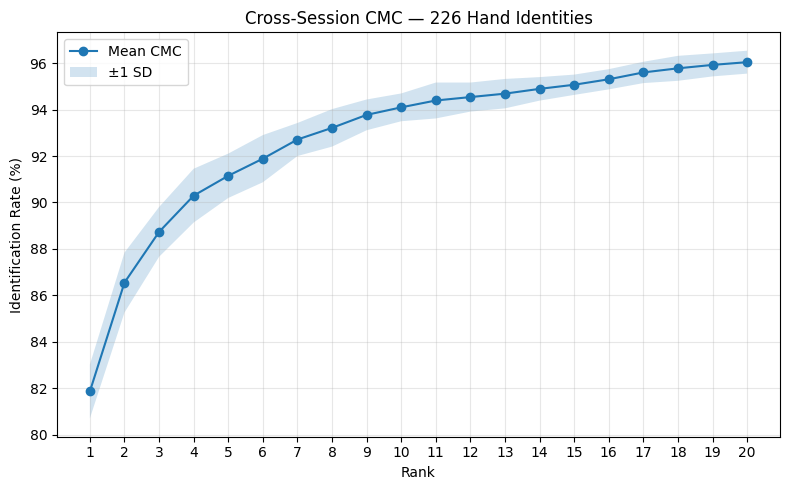

In [ ]:
# ============================================================
# CMC CURVE — MEAN ± SD
# ============================================================

cmcs = np.stack([
    seed_eval[
        seed
    ]["identification"]["cmc"]

    for seed in SEEDS
])

mean_cmc = cmcs.mean(
    axis=0
)

std_cmc = cmcs.std(
    axis=0,
    ddof=1
)

ranks = np.arange(
    1,
    CMC_MAX_RANK + 1
)


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    ranks,
    mean_cmc * 100,
    marker="o",
    label="Mean CMC"
)

plt.fill_between(
    ranks,

    (
        mean_cmc
        - std_cmc
    ) * 100,

    (
        mean_cmc
        + std_cmc
    ) * 100,

    alpha=0.2,
    label="±1 SD"
)

plt.xlabel(
    "Rank"
)

plt.ylabel(
    "Identification Rate (%)"
)

plt.title(
    "Cross-Session CMC — "
    "226 Hand Identities"
)

plt.xticks(
    ranks
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(
    BIO_DIR /
    "cmc_5seeds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

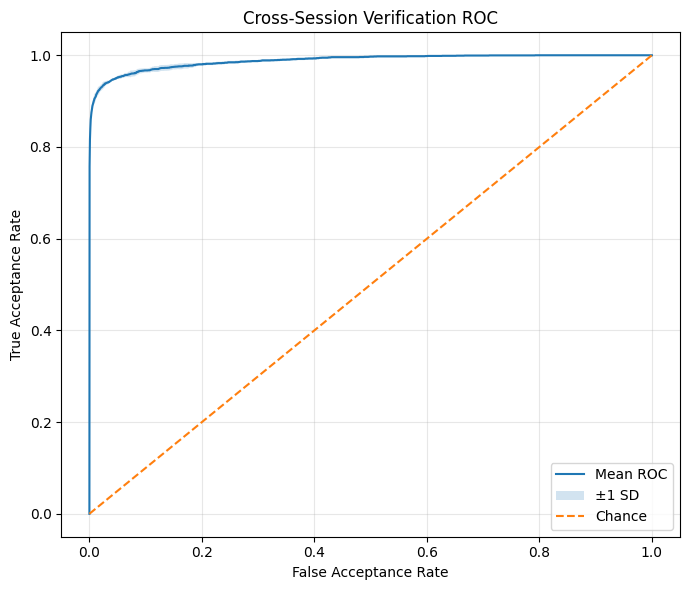

In [ ]:
# ============================================================
# ROC — FIVE-SEED MEAN
# ============================================================

common_fpr = np.linspace(
    0,
    1,
    3000
)

all_tpr = []

for seed in SEEDS:

    v = seed_eval[
        seed
    ]["verification"]

    interpolated = np.interp(
        common_fpr,
        v["fpr"],
        v["tpr"]
    )

    interpolated[0] = 0

    all_tpr.append(
        interpolated
    )


all_tpr = np.stack(
    all_tpr
)

mean_tpr = all_tpr.mean(
    axis=0
)

std_tpr = all_tpr.std(
    axis=0,
    ddof=1
)


plt.figure(
    figsize=(7, 6)
)

plt.plot(
    common_fpr,
    mean_tpr,
    label="Mean ROC"
)

plt.fill_between(
    common_fpr,

    np.maximum(
        mean_tpr - std_tpr,
        0
    ),

    np.minimum(
        mean_tpr + std_tpr,
        1
    ),

    alpha=0.2,
    label="±1 SD"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel(
    "False Acceptance Rate"
)

plt.ylabel(
    "True Acceptance Rate"
)

plt.title(
    "Cross-Session Verification ROC"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(
    BIO_DIR /
    "roc_5seeds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

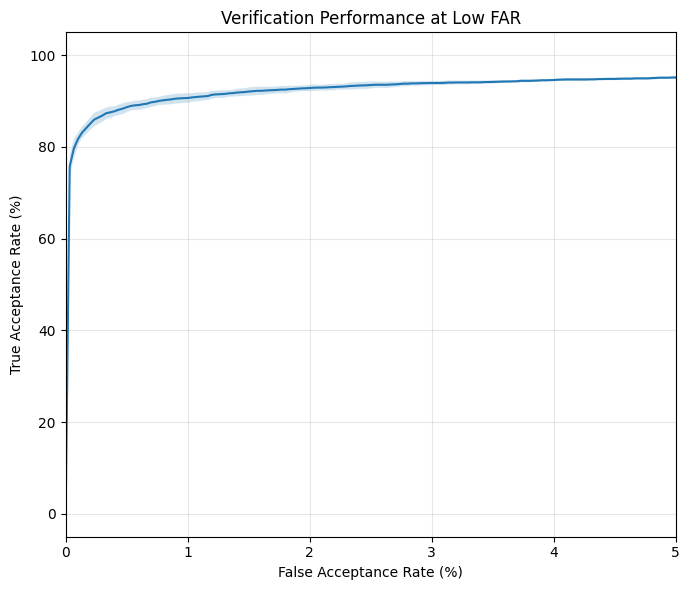

In [ ]:
# ============================================================
# LOW-FAR ROC
# ============================================================

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    common_fpr * 100,
    mean_tpr * 100
)

plt.fill_between(
    common_fpr * 100,

    np.maximum(
        mean_tpr - std_tpr,
        0
    ) * 100,

    np.minimum(
        mean_tpr + std_tpr,
        1
    ) * 100,

    alpha=0.2
)

plt.xlim(
    0,
    5
)

plt.xlabel(
    "False Acceptance Rate (%)"
)

plt.ylabel(
    "True Acceptance Rate (%)"
)

plt.title(
    "Verification Performance "
    "at Low FAR"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    BIO_DIR /
    "roc_low_far.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

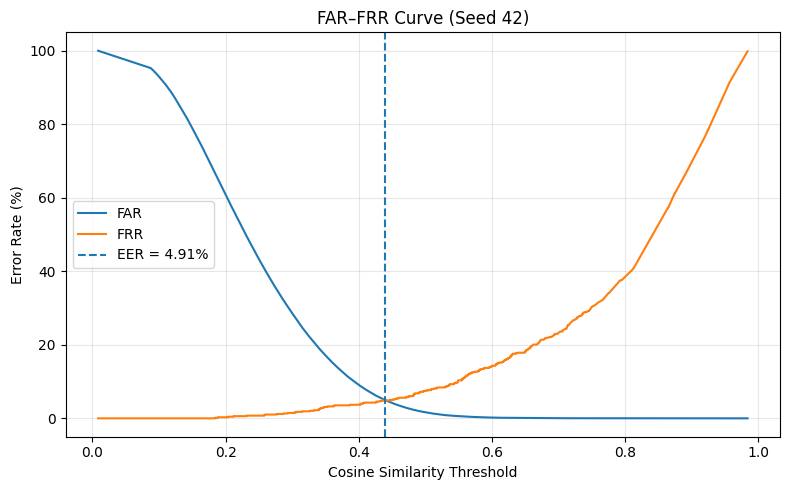

In [ ]:
# ============================================================
# FAR / FRR / EER VISUALIZATION
# ============================================================

seed = 42

v = seed_eval[
    seed
]["verification"]

finite = np.isfinite(
    v["thresholds"]
)

thresholds = (
    v["thresholds"][
        finite
    ]
)

far = (
    v["fpr"][
        finite
    ]
)

frr = (
    v["fnr"][
        finite
    ]
)


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    thresholds,
    far * 100,
    label="FAR"
)

plt.plot(
    thresholds,
    frr * 100,
    label="FRR"
)

plt.axvline(
    v["eer_threshold"],
    linestyle="--",
    label=(
        f"EER = "
        f"{v['eer']*100:.2f}%"
    )
)

plt.xlabel(
    "Cosine Similarity Threshold"
)

plt.ylabel(
    "Error Rate (%)"
)

plt.title(
    "FAR–FRR Curve "
    "(Seed 42)"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(
    BIO_DIR /
    "far_frr_eer_seed42.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

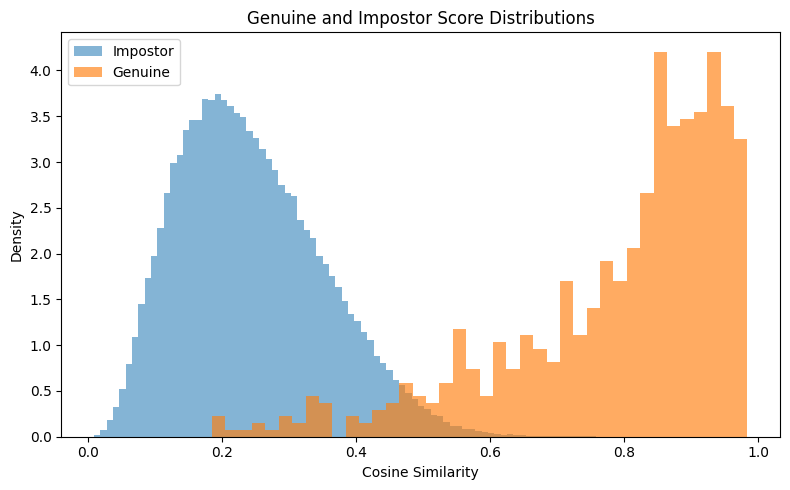

Genuine mean: 0.7912845
Impostor mean: 0.2434875


In [ ]:
# ============================================================
# GENUINE / IMPOSTOR DISTRIBUTION
# ============================================================

seed = 42

genuine = seed_eval[
    seed
]["genuine"]

impostor = seed_eval[
    seed
]["impostor"]


plt.figure(
    figsize=(8, 5)
)

plt.hist(
    impostor,
    bins=100,
    density=True,
    alpha=0.55,
    label="Impostor"
)

plt.hist(
    genuine,
    bins=40,
    density=True,
    alpha=0.65,
    label="Genuine"
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Genuine and Impostor "
    "Score Distributions"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    BIO_DIR /
    "genuine_impostor_seed42.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Genuine mean:",
    genuine.mean()
)

print(
    "Impostor mean:",
    impostor.mean()
)

In [ ]:
# ============================================================
# PER-IDENTITY ERROR ANALYSIS
# ============================================================

seed = 42

labels = seed_eval[
    seed
]["labels"]

predictions = seed_eval[
    seed
]["identification"][
    "predictions"
]


identity_rows = []

for identity in range(
    NUM_CLASSES
):

    mask = (
        labels == identity
    )

    accuracy = np.mean(
        predictions[mask]
        == labels[mask]
    )

    person = (
        identity // 2
    ) + 1

    hand = (
        "L"
        if identity % 2 == 0
        else "R"
    )

    identity_rows.append({

        "class_id":
            identity,

        "person":
            person,

        "hand":
            hand,

        "correct":
            int(
                np.sum(
                    predictions[mask]
                    == labels[mask]
                )
            ),

        "total":
            int(mask.sum()),

        "accuracy":
            float(accuracy)
    })


identity_performance = (
    pd.DataFrame(
        identity_rows
    )
    .sort_values(
        [
            "accuracy",
            "person",
            "hand"
        ]
    )
    .reset_index(drop=True)
)


print(
    "Hardest hand identities:"
)

display(
    identity_performance.head(
        30
    )
)

identity_performance.to_csv(
    BIO_DIR /
    "identity_error_analysis_seed42.csv",
    index=False
)

Hardest hand identities:


,class_id,person,hand,correct,total,accuracy
0,3,2,R,0,3,0.000000
1,6,4,L,0,3,0.000000
2,7,4,R,0,3,0.000000
3,10,6,L,0,3,0.000000
4,11,6,R,0,3,0.000000
5,17,9,R,0,3,0.000000
6,34,18,L,0,3,0.000000
7,40,21,L,0,3,0.000000
8,43,22,R,0,3,0.000000
9,46,24,L,0,3,0.000000


In [ ]:
# ============================================================
# LEFT VS RIGHT PERFORMANCE
# ============================================================

left_mask = (
    labels % 2 == 0
)

right_mask = (
    labels % 2 == 1
)

left_acc = np.mean(
    predictions[left_mask]
    == labels[left_mask]
)

right_acc = np.mean(
    predictions[right_mask]
    == labels[right_mask]
)

print(
    f"Left-hand Rank-1 : "
    f"{left_acc*100:.2f}%"
)

print(
    f"Right-hand Rank-1: "
    f"{right_acc*100:.2f}%"
)

Left-hand Rank-1 : 79.94%
Right-hand Rank-1: 83.78%


In [ ]:
# ============================================================
# CONFUSION PAIRS
# ============================================================

cm = confusion_matrix(
    labels,
    predictions,
    labels=np.arange(
        NUM_CLASSES
    )
)

confusion_rows = []

for true_id in range(
    NUM_CLASSES
):

    for pred_id in range(
        NUM_CLASSES
    ):

        if (
            true_id == pred_id
            or cm[
                true_id,
                pred_id
            ] == 0
        ):
            continue

        confusion_rows.append({

            "true_class":
                true_id,

            "true_person":
                true_id // 2 + 1,

            "true_hand":
                (
                    "L"
                    if true_id % 2 == 0
                    else "R"
                ),

            "pred_class":
                pred_id,

            "pred_person":
                pred_id // 2 + 1,

            "pred_hand":
                (
                    "L"
                    if pred_id % 2 == 0
                    else "R"
                ),

            "count":
                int(
                    cm[
                        true_id,
                        pred_id
                    ]
                )
        })


confusion_pairs = (
    pd.DataFrame(
        confusion_rows
    )
    .sort_values(
        "count",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    confusion_pairs.head(
        30
    )
)

confusion_pairs.to_csv(
    BIO_DIR /
    "confusion_pairs_seed42.csv",
    index=False
)

,true_class,true_person,true_hand,pred_class,pred_person,pred_hand,count
0,6,4,L,7,4,R,3
1,7,4,R,6,4,L,3
2,178,90,L,180,91,L,3
3,176,89,L,74,38,L,3
4,210,106,L,59,30,R,3
5,168,85,L,86,44,L,3
6,162,82,L,59,30,R,3
7,170,86,L,190,96,L,3
8,60,31,L,114,58,L,3
9,49,25,R,143,72,R,3


In [ ]:
# ============================================================
# OPPOSITE-HAND CONFUSION ANALYSIS
# ============================================================

errors = (
    predictions != labels
)

true_error = labels[
    errors
]

pred_error = predictions[
    errors
]


same_person_opposite_hand = 0

for true_id, pred_id in zip(
    true_error,
    pred_error
):

    true_person = (
        true_id // 2
    )

    pred_person = (
        pred_id // 2
    )

    different_hand = (
        true_id % 2
        != pred_id % 2
    )

    if (
        true_person
        == pred_person
        and different_hand
    ):
        same_person_opposite_hand += 1


total_errors = len(
    true_error
)

rate = (
    same_person_opposite_hand
    / total_errors
    if total_errors > 0
    else 0
)


print(
    "Total Rank-1 errors:",
    total_errors
)

print(
    "Same-person opposite-hand errors:",
    same_person_opposite_hand
)

print(
    "Percentage of errors involving "
    "the opposite hand of the same person:"
)

print(
    f"{rate*100:.2f}%"
)

Total Rank-1 errors: 123
Same-person opposite-hand errors: 6
Percentage of errors involving the opposite hand of the same person:
4.88%
